In [2]:
import numpy as np
import math
import qutip as qt
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed
import pickle

# ============================================================
#  通用参数
# ============================================================
CAT_TYPE               = "even"
N_DIM               = 50
ALPHA_IN_MIN       = 0.3
ALPHA_IN_MAX       = 2.5
ALPHA_IN_NPTS      = 35
RESTART_SEEDS      = [42, 123, 7]
SMALL_ALPHA_THRESHOLD = 0.8
DE_MAXITER_SMALL   = 150
DE_POPSIZE_SMALL   = 20
DE_MAXITER_LARGE   = 80
DE_POPSIZE_LARGE   = 12
N_WORKERS          = 4

cases = [
    {
        'label'      : 'm=n=1, g=1.1',
        'n'          : 1,
        'g'          : 1.1,
        'allow_atten': True,
        'at_min'     : 0.05,
        'at_max'     : 5.0,
        'at_offset'  : None
    },
    {
        'label'      : 'm=n=2, g=2.8',
        'n'          : 2,
        'g'          : 2.8,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=3, g=1.93',  # 修正了原注中 g=2.0 实际为 1.93 的不一致
        'n'          : 3,
        'g'          : 1.93,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=4, g=1.65',
        'n'          : 4,
        'g'          : 1.65,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    }
]

# ============================================================
#  工具函数
# ============================================================
def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a    = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim,  alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * math.factorial(n) /
        (math.factorial(k)**2 * math.factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs

def precompute_cat_base(alpha_target, cat_type, N_dim):
    alpha_plus  = qt.coherent(N_dim,  alpha_target)
    alpha_minus = qt.coherent(N_dim, -alpha_target)
    base_cat = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
               else (alpha_plus - alpha_minus).unit()
    return base_cat.full().flatten()

def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G      = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out

def squeeze_vec(cat_vec, gamma, N_dim):
    S_mat = qt.squeeze(N_dim, gamma).full()
    sv    = S_mat @ cat_vec
    norm  = np.linalg.norm(sv)
    return sv / norm if norm > 1e-15 else sv

def optimize_one(alpha_in, case, N_dim, restart_seeds,
                 small_alpha_threshold, de_maxiter_small, de_popsize_small,
                 de_maxiter_large, de_popsize_large):
    n           = case['n']
    g           = case['g']
    allow_atten = case['allow_atten']
    at_min      = case['at_min']
    at_max      = case['at_max']
    at_offset   = case['at_offset']
    cat_type    = CAT_TYPE

    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(alpha_in, n, cat_type, N_dim)
    psi_out = fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)

    if allow_atten:
        bounds = [(at_min, at_max), (0.0, 2.0)]
    else:
        bounds = [(alpha_in + 0.05, alpha_in + at_offset), (0.0, 2.0)]

    is_small = alpha_in < small_alpha_threshold
    maxiter  = de_maxiter_small if is_small else de_maxiter_large
    popsize  = de_popsize_small if is_small else de_popsize_large

    def cost(x):
        alpha_target, gamma = x
        try:
            cat_vec = precompute_cat_base(alpha_target, cat_type, N_dim)
            psi_tgt = squeeze_vec(cat_vec, gamma, N_dim)
            return -abs(np.dot(psi_out.conj(), psi_tgt))**2
        except Exception:
            return 1.0

    best_F = -1.0
    best_x = None
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds, strategy='best1bin',
            maxiter=maxiter, popsize=popsize, seed=seed,
            tol=1e-6, disp=False
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    at_opt, r_opt = best_x
    return float(alpha_in), best_F, float(at_opt), float(r_opt)

if __name__ == '__main__':
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)
    all_results = {}

    for case in cases:
        label = case['label']
        print(f"\n{'='*60}\n  Running case: {label}\n{'='*60}")

        raw = Parallel(n_jobs=N_WORKERS, backend='loky', verbose=5)(
            delayed(optimize_one)(
                ai, case, N_DIM, RESTART_SEEDS,
                SMALL_ALPHA_THRESHOLD, DE_MAXITER_SMALL, DE_POPSIZE_SMALL,
                DE_MAXITER_LARGE, DE_POPSIZE_LARGE
            ) for ai in alpha_in_arr
        )

        raw.sort(key=lambda r: r[0])
        all_results[label] = raw

        print(f"\n  {'α_in':>6}  {'α_tgt':>6}  {'amp':>6}  {'F':>7}  {'r':>6}")
        print(f"  {'-'*6}  {'-'*6}  {'-'*6}  {'-'*7}  {'-'*6}")
        for r in raw:
            ai, F, at, rv = r
            flag = " ▲" if at > ai else (" ▼" if at < ai else "  ")
            print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:6.3f}{flag}  {F:7.4f}  {rv:6.3f}")

    # 🌟 将计算结果序列化保存到本地文件
    with open('catalysis_results.pkl', 'wb') as f:
        pickle.dump(all_results, f)
    print("\n[SUCCESS] 所有计算数据已成功保存至 'catalysis_results.pkl'")


  Running case: m=n=1, g=1.1


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   40.7s
[Parallel(n_jobs=4)]: Done  35 out of  35 | elapsed:  1.8min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.220   0.733 ▼   1.0000   0.005
   0.365   0.267   0.733 ▼   1.0000   0.008
   0.429   0.315   0.735 ▼   1.0000   0.011
   0.494   0.363   0.734 ▼   1.0000   0.015
   0.559   0.410   0.734 ▼   1.0000   0.018
   0.624   0.458   0.734 ▼   1.0000   0.023
   0.688   0.505   0.734 ▼   1.0000   0.028
   0.753   0.553   0.735 ▼   1.0000   0.034
   0.818   0.601   0.735 ▼   1.0000   0.040
   0.882   0.649   0.735 ▼   1.0000   0.047
   0.947   0.697   0.736 ▼   1.0000   0.054
   1.012   0.745   0.736 ▼   1.0000   0.062
   1.076   0.794   0.737 ▼   0.9999   0.071
   1.141   0.842   0.738 ▼   0.9999   0.080
   1.206   0.892   0.739 ▼   0.9998   0.091
   1.271   0.941   0.741 ▼   0.9996   0.102
   1.335   0.992   0.743 ▼   0.9993   0.114
   1.400   1.043   0.745 ▼   0.9988   0.127
   1.465   1.096   0.748 ▼   0.9979   0.141
   1.529   1.150   0.752 ▼   0.9965   0.157
   1.594   1.206   0.756 ▼   0.9942

[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   37.8s
[Parallel(n_jobs=4)]: Done  35 out of  35 | elapsed:  1.6min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.510   1.699 ▲   1.0000   0.025
   0.365   0.620   1.700 ▲   1.0000   0.037
   0.429   0.730   1.701 ▲   1.0000   0.052
   0.494   0.841   1.702 ▲   1.0000   0.068
   0.559   0.952   1.704 ▲   1.0000   0.087
   0.624   1.064   1.707 ▲   1.0000   0.108
   0.688   1.177   1.710 ▲   1.0000   0.130
   0.753   1.289   1.712 ▲   0.9999   0.154
   0.818   1.401   1.714 ▲   0.9998   0.179
   0.882   1.512   1.714 ▲   0.9996   0.203
   0.947   1.621   1.711 ▲   0.9993   0.227
   1.012   1.726   1.706 ▲   0.9990   0.250
   1.076   1.828   1.699 ▲   0.9986   0.272
   1.141   1.928   1.689 ▲   0.9982   0.293
   1.206   2.025   1.679 ▲   0.9975   0.313
   1.271   2.119   1.668 ▲   0.9967   0.333
   1.335   2.211   1.655 ▲   0.9957   0.353
   1.400   2.299   1.642 ▲   0.9943   0.371
   1.465   2.383   1.627 ▲   0.9924   0.388
   1.529   2.463   1.610 ▲   0.9902   0.404
   1.594   2.537   1.592 ▲   0.9875

[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   36.7s
[Parallel(n_jobs=4)]: Done  35 out of  35 | elapsed:  1.6min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.435   1.451 ▲   1.0000   0.022
   0.365   0.529   1.451 ▲   1.0000   0.033
   0.429   0.624   1.452 ▲   1.0000   0.045
   0.494   0.718   1.453 ▲   1.0000   0.060
   0.559   0.813   1.455 ▲   1.0000   0.077
   0.624   0.909   1.458 ▲   1.0000   0.096
   0.688   1.006   1.462 ▲   1.0000   0.118
   0.753   1.104   1.467 ▲   1.0000   0.141
   0.818   1.205   1.474 ▲   1.0000   0.168
   0.882   1.309   1.484 ▲   0.9999   0.198
   0.947   1.418   1.497 ▲   0.9998   0.231
   1.012   1.533   1.515 ▲   0.9997   0.269
   1.076   1.657   1.540 ▲   0.9995   0.311
   1.141   1.792   1.571 ▲   0.9991   0.358
   1.206   1.939   1.608 ▲   0.9986   0.410
   1.271   2.097   1.650 ▲   0.9975   0.464
   1.335   2.263   1.695 ▲   0.9956   0.521
   1.400   2.436   1.740 ▲   0.9921   0.577
   1.465   2.610   1.782 ▲   0.9862   0.632
   1.529   2.785   1.821 ▲   0.9766   0.684
   1.594   2.956   1.855 ▲   0.9622

[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   37.3s



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.440   1.466 ▲   1.0000   0.027
   0.365   0.535   1.467 ▲   1.0000   0.040
   0.429   0.630   1.468 ▲   1.0000   0.056
   0.494   0.726   1.470 ▲   1.0000   0.074
   0.559   0.823   1.472 ▲   1.0000   0.095
   0.624   0.920   1.476 ▲   1.0000   0.118
   0.688   1.019   1.481 ▲   1.0000   0.144
   0.753   1.120   1.487 ▲   1.0000   0.173
   0.818   1.223   1.496 ▲   1.0000   0.205
   0.882   1.329   1.506 ▲   1.0000   0.239
   0.947   1.439   1.520 ▲   0.9999   0.276
   1.012   1.554   1.536 ▲   0.9999   0.316
   1.076   1.673   1.554 ▲   0.9997   0.359
   1.141   1.798   1.576 ▲   0.9994   0.404
   1.206   1.930   1.600 ▲   0.9988   0.451
   1.271   2.070   1.629 ▲   0.9977   0.500
   1.335   2.218   1.661 ▲   0.9959   0.551
   1.400   2.375   1.697 ▲   0.9927   0.604
   1.465   2.541   1.735 ▲   0.9876   0.658
   1.529   2.712   1.773 ▲   0.9795   0.712
   1.594   2.887   1.811 ▲   0.9674

[Parallel(n_jobs=4)]: Done  35 out of  35 | elapsed:  1.7min finished


[SUCCESS] 曲线上的标点密度已成功抽稀（每 3 个点标注一次）。


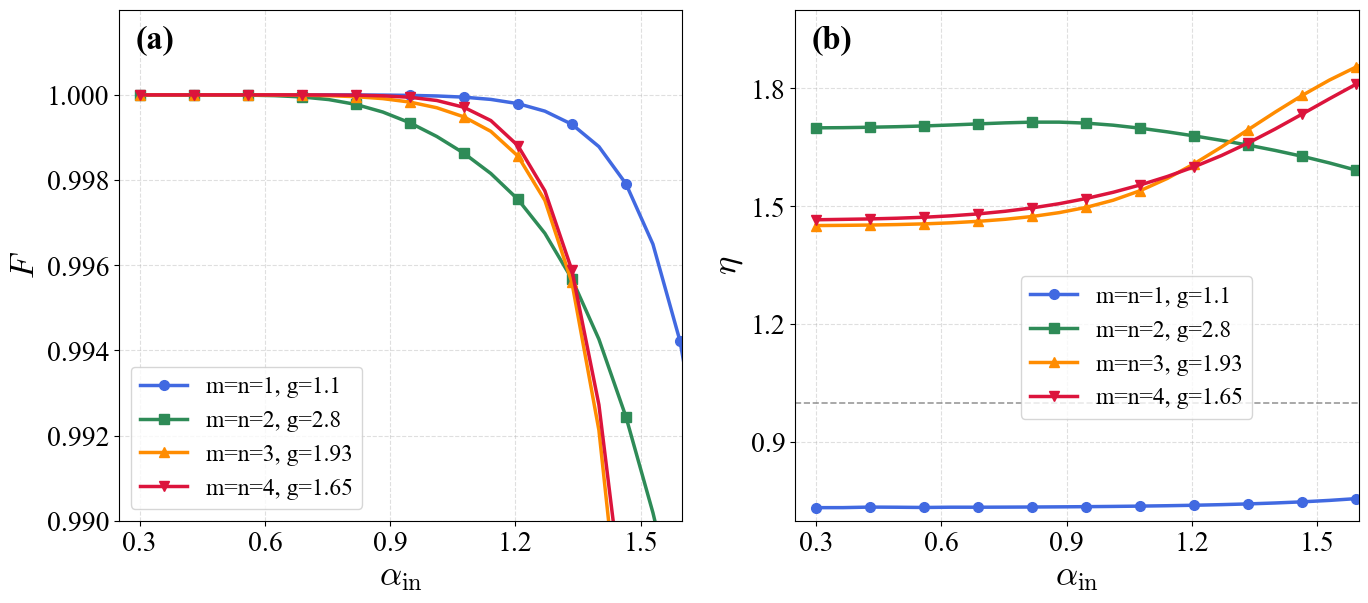

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
import pickle

# 设置科学论文常用的经典字体样式
mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

def main():
    # 从本地文件读取计算好的数据
    try:
        with open('catalysis_results.pkl', 'rb') as f:
            all_results = pickle.load(f)
    except FileNotFoundError:
        print("[ERROR] 找不到 'catalysis_results.pkl' 文件，请先运行第一段数据计算代码！")
        return

    # 创建画布
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
    fig.subplots_adjust(wspace=0.2, bottom=0.15)

    colors = ['royalblue', 'seagreen', 'darkorange', 'crimson']
    markers = ['o', 's', '^', 'v']

    for (label, data), color, marker in zip(all_results.items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        # 放大倍率 η = α_tgt / α_in
        amps       = np.array([d[2] for d in data]) / alpha_vals

        # 🌟 核心修改：使用 markevery=3，让原本 25 个点密密麻麻的标记变成每隔 3 个点才显示一个
        # 子图 (a): 保真度 Fidelity
        ax1.plot(alpha_vals, fids, marker=marker, color=color,
                 lw=2.5, ms=7, markevery=2, label=label)
        
        # 子图 (b): 振幅放大率 η
        ax2.plot(alpha_vals, amps, marker=marker, color=color,
                 lw=2.5, ms=7, markevery=2, label=label)

    # ========================================================
    # 子图 (a) 样式配置（Fidelity）
    # ========================================================
    ax1.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=25)
    ax1.set_ylabel(r'$F$', fontsize=25)
    
    # 限制范围并手动指定刻度
    ax1.set_ylim(0.99, 1.002)
    ax1.set_xlim(0.25, 1.6)
    ax1.set_yticks([0.990, 0.992,0.994,0.996,0.998, 1.00])
    
    # 减少 X 轴刻度标签数量（最多 5 个）
    ax1.xaxis.set_major_locator(MaxNLocator(nbins=5))
    
    # 保持三位小数显示：0.980, 0.990, 1.000
    ax1.yaxis.set_major_formatter(FormatStrFormatter('%.3f'))
    
    # 放大刻度数字字体
    ax1.tick_params(axis='both', labelsize=20)
    
    ax1.grid(True, ls='--', alpha=0.4)
    ax1.legend(fontsize=17, loc='lower left')
    ax1.text(0.03, 0.97, '(a)', transform=ax1.transAxes, fontsize=24, fontweight='bold', va='top')

    # ========================================================
    # 子图 (b) 样式配置（η）
    # ========================================================
    ax2.axhline(1.0, color='grey', ls='--', lw=1.2, alpha=0.8)
    ax2.set_xlim(0.25, 1.6)
    ax2.set_ylim(0.7, 2.0)
    ax2.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=25)
    ax2.set_ylabel(r'$\eta$', fontsize=25)
    
    # 减少刻度标签数量
    ax2.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax2.yaxis.set_major_locator(MaxNLocator(nbins=5))
    
    # 放大刻度数字字体
    ax2.tick_params(axis='both', labelsize=20)
    
    ax2.grid(True, ls='--', alpha=0.4)
    ax2.legend(fontsize=17, loc=(0.4, 0.2))
   
    ax2.text(0.03, 0.97, '(b)', transform=ax2.transAxes, fontsize=24, fontweight='bold', va='top', ha='left')

    
    plt.savefig('catalysis_comparison.pdf', bbox_inches='tight', dpi=150)
    plt.savefig('catalysis_comparison.png', bbox_inches='tight', dpi=150)
    print("[SUCCESS] 曲线上的标点密度已成功抽稀（每 3 个点标注一次）。")
    plt.show()

if __name__ == '__main__':
    main()

In [5]:
import pickle
import numpy as np
from scipy.interpolate import interp1d

# ============================================================
# 配置参数
# ============================================================
FILE_NAME = 'catalysis_results.pkl'
TARGET_F = 0.99

def extract_target_fidelity_data(file_name, target_f):
    # 1. 加载本地数据
    try:
        with open(file_name, 'rb') as f:
            all_results = pickle.load(f)
    except FileNotFoundError:
        print(f"[错误] 找不到文件 {file_name}，请确保前置脚本已成功运行。")
        return

    print(f"========== 提取保真度 F = {target_f} 对应的内组数据 ==========\n")
    
    # 2. 遍历四种情况进行插值
    for label, raw in all_results.items():
        raw_arr = np.array(raw)
        ai_arr = raw_arr[:, 0]
        F_arr  = raw_arr[:, 1]
        at_arr = raw_arr[:, 2]
        r_arr  = raw_arr[:, 3]

        # 检查 target_F 是否在当前数据的数值范围内
        f_min, f_max = F_arr.min(), F_arr.max()
        if target_f < f_min or target_f > f_max:
            print(f"[{label}]")
            print(f"  ⚠️ 目标 F={target_f} 不在当前计算范围内 (F_min={f_min:.4f}, F_max={f_max:.4f})")
            print("-" * 60)
            continue

        # 针对 F 进行排序，确保插值函数 (interp1d) 正常工作
        # （物理上，随着 α_in 增大，F 通常是单调递减的，排序以防万一）
        sort_idx = np.argsort(F_arr)
        F_sorted = F_arr[sort_idx]
        ai_sorted = ai_arr[sort_idx]
        at_sorted = at_arr[sort_idx]
        r_sorted  = r_arr[sort_idx]

        # 使用线性插值 (可根据需要改为 'cubic' 三次样条插值)
        interp_ai = interp1d(F_sorted, ai_sorted, kind='linear')(target_f)
        interp_at = interp1d(F_sorted, at_sorted, kind='linear')(target_f)
        interp_r  = interp1d(F_sorted, r_sorted, kind='linear')(target_f)
        
        # 计算放大倍数
        amp = interp_at / interp_ai

        # 打印结果
        print(f"[{label}]")
        print(f"  初始相干态幅度 (α_in)   = {float(interp_ai):.4f}")
        print(f"  目标相干态幅度 (α_tgt)  = {float(interp_at):.4f}")
        print(f"  放大倍数       (amp)    = {float(amp):.4f}")
        print(f"  挤压参数       (r)      = {float(interp_r):.4f}")
        print("-" * 60)

if __name__ == '__main__':
    extract_target_fidelity_data(FILE_NAME, TARGET_F)

========== 提取保真度 F = 0.99 对应的内组数据 ==========

[m=n=1, g=1.1]
  初始相干态幅度 (α_in)   = 1.6665
  目标相干态幅度 (α_tgt)  = 1.2712
  放大倍数       (amp)    = 0.7628
  挤压参数       (r)      = 0.1947
------------------------------------------------------------
[m=n=2, g=2.8]
  初始相干态幅度 (α_in)   = 1.5339
  目标相干态幅度 (α_tgt)  = 2.4680
  放大倍数       (amp)    = 1.6090
  挤压参数       (r)      = 0.4045
------------------------------------------------------------
[m=n=3, g=1.93]
  初始相干态幅度 (α_in)   = 1.4232
  目标相干态幅度 (α_tgt)  = 2.4981
  放大倍数       (amp)    = 1.7553
  挤压参数       (r)      = 0.5965
------------------------------------------------------------
[m=n=4, g=1.65]
  初始相干态幅度 (α_in)   = 1.4341
  目标相干态幅度 (α_tgt)  = 2.4626
  放大倍数       (amp)    = 1.7172
  挤压参数       (r)      = 0.6328
------------------------------------------------------------
